# 06. 条件付け（Conditioning）：img2img・ControlNet・IP-Adapter で生成AIを「縛る」

**セミナー対応章**：第3章（4）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU　｜　**所要時間**：約7分（モデルDL 約6GB を含まず）

生成AIで復元するとき、自由に描かせすぎると **元画像の特徴（構造・色・質感・意味）** が失われます。
1. **img2img**：strength（どれだけノイズを足して描き直すか）で自由度を調整 → 構造が崩れるジレンマ
2. **ControlNet（Tile / Canny）**：構造で縛る
3. **IP-Adapter**：参照画像の「意味・質感」で縛る（CLIP画像埋め込みをクロスアテンションに注入）
4. **併用**：ControlNet × img2img × IP-Adapter
5. **実践例**：5段階パイプラインで低画質な人物写真を高品質化（各段階で画質が上がる様子を確認）

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


## 0. 入力画像：低画質な画像（縮小→拡大でぼやけた画像）

W1030 15:32:22.978000 61328 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


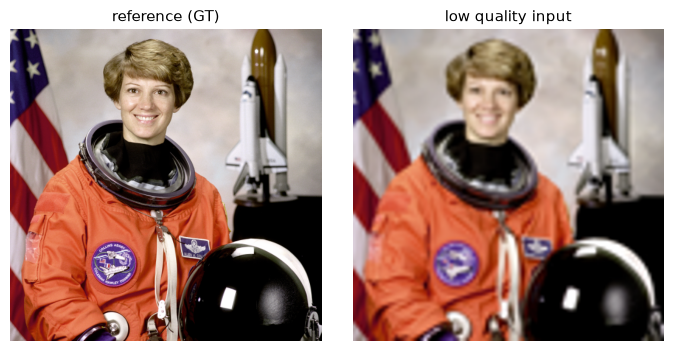

In [2]:
import cv2
from diffusers import (StableDiffusionImg2ImgPipeline, StableDiffusionControlNetImg2ImgPipeline,
                       StableDiffusionControlNetPipeline, ControlNetModel)

hr = load_sample("astronaut")
lq = hr.resize((96, 96), Image.BICUBIC).resize((512, 512), Image.BICUBIC)
PROMPT = "a high quality photo of an astronaut, detailed, sharp focus"
NEG = "blurry, low quality, cartoon, painting, deformed"
gen = lambda s=0: torch.Generator(DEVICE).manual_seed(s)
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
show([hr, lq], ["reference (GT)", "low quality input"], size=3.5)

## 1. img2img：strength のジレンマ
strength が小さい → ほとんど変わらない（ぼやけたまま）／大きい → きれいになるが **別人・別の構図** になる

D:\seminar_env\venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


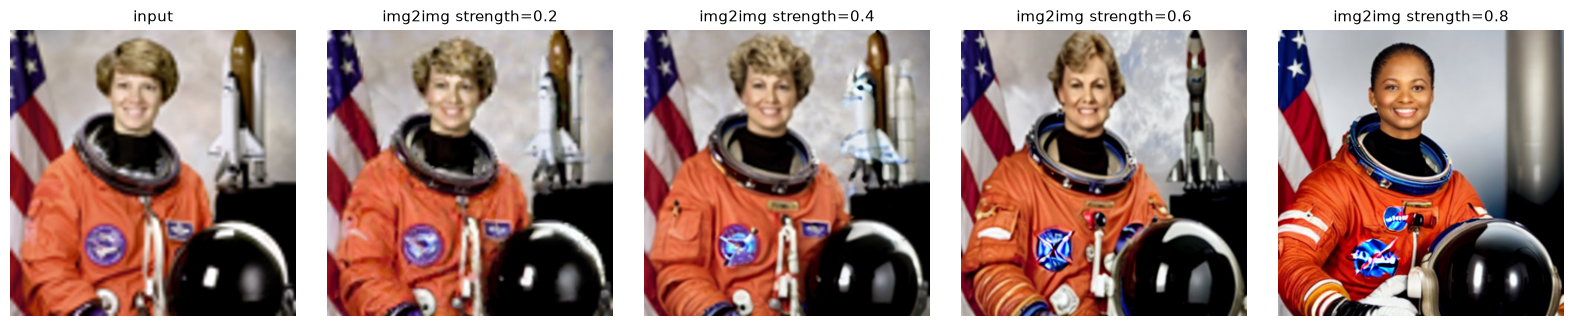

In [3]:
i2i = StableDiffusionImg2ImgPipeline.from_pretrained(BASE, torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
i2i.set_progress_bar_config(disable=True)
strengths = [0.2, 0.4, 0.6, 0.8]
outs = [i2i(PROMPT, image=lq, strength=s, negative_prompt=NEG, num_inference_steps=30, generator=gen()).images[0]
        for s in strengths]
show([lq] + outs, ["input"] + [f"img2img strength={s}" for s in strengths], size=3.2)
del i2i; torch.cuda.empty_cache() if DEVICE == "cuda" else None

## 2. ControlNet Tile：入力画像そのものを「構造の設計図」にする
ControlNet は元の拡散モデルを凍結したまま、条件画像（エッジ・深度・ぼやけた画像など）から構造情報を注入する追加ネットワークです。
**Tile** 版は「ぼやけた画像の構造は守りつつ細部を描き足す」ように学習されており、超解像・高品質化に向きます。

D:\seminar_env\venv\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


An error occurred while trying to fetch lllyasviel/control_v11f1e_sd15_tile: lllyasviel/control_v11f1e_sd15_tile does not appear to have a file named diffusion_pytorch_model.safetensors.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet_img2img.StableDiffusionControlNetImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


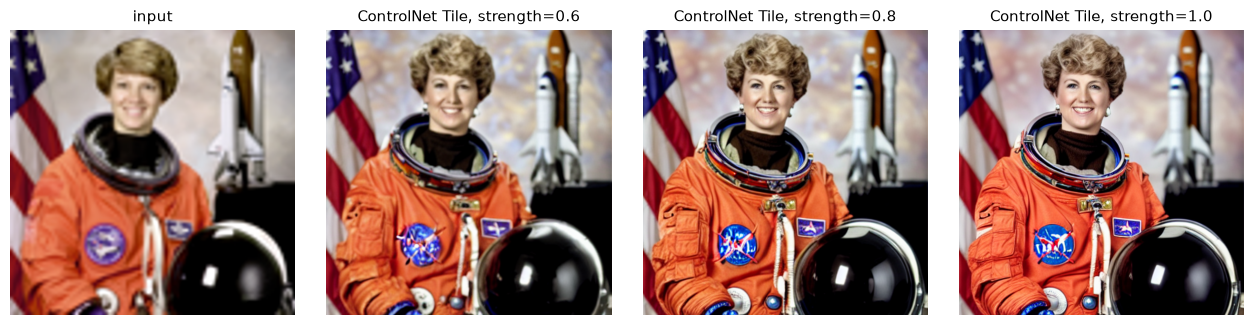

GPUメモリ使用量(ピーク): 3.33 GB


In [4]:
cn_tile = ControlNetModel.from_pretrained("lllyasviel/control_v11f1e_sd15_tile", torch_dtype=DTYPE)
pipe = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    BASE, controlnet=cn_tile, torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
pipe.set_progress_bar_config(disable=True)

tile_outs = [pipe(PROMPT, image=lq, control_image=lq, strength=s, negative_prompt=NEG,
                  num_inference_steps=30, controlnet_conditioning_scale=1.0, generator=gen()).images[0]
             for s in (0.6, 0.8, 1.0)]
show([lq] + tile_outs, ["input"] + [f"ControlNet Tile, strength={s}" for s in (0.6, 0.8, 1.0)], size=3.2)
gpu_mem()

**観察ポイント**：img2img の strength=0.8 では構図が崩れましたが、ControlNet Tile では strength=1.0（完全にノイズから生成）でも構図・顔の向きが保たれます。

## 3. ControlNet Canny：エッジ（輪郭）だけで縛る
輪郭は守り、色や質感は自由に生成させたい場合（例：線画・CAD図面から写真風画像、疑似欠陥画像の生成）に使います。

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


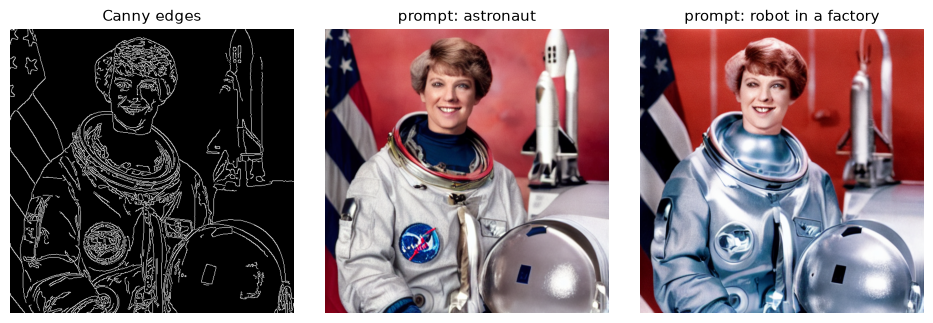

In [5]:
edges = cv2.Canny(np.array(hr), 100, 200)
edge_img = Image.fromarray(np.stack([edges] * 3, -1))
cn_canny = ControlNetModel.from_pretrained("lllyasviel/control_v11p_sd15_canny", torch_dtype=DTYPE)
canny_pipe = StableDiffusionControlNetPipeline.from_pretrained(
    BASE, controlnet=cn_canny, torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
canny_pipe.set_progress_bar_config(disable=True)
canny_outs = [canny_pipe(p, image=edge_img, negative_prompt=NEG, num_inference_steps=30, generator=gen()).images[0]
              for p in ["a photo of an astronaut", "a photo of a robot in a factory"]]
show([edge_img] + canny_outs, ["Canny edges", "prompt: astronaut", "prompt: robot in a factory"], size=3.2)
del canny_pipe, cn_canny; torch.cuda.empty_cache() if DEVICE == "cuda" else None

## 4. IP-Adapter：参照画像の「意味・質感」で縛る
テキストでは「この製品のこの質感」を正確に伝えられません。IP-Adapter は参照画像を CLIP 画像エンコーダで埋め込み、
**テキストとは別のクロスアテンション** として U-Net に注入します（Decoupled Cross-Attention）。
ここでは、ControlNet Tile（構造）に加えて、**高画質な参照画像**（同じ被写体の良品画像を想定）で質感を縛ります。

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


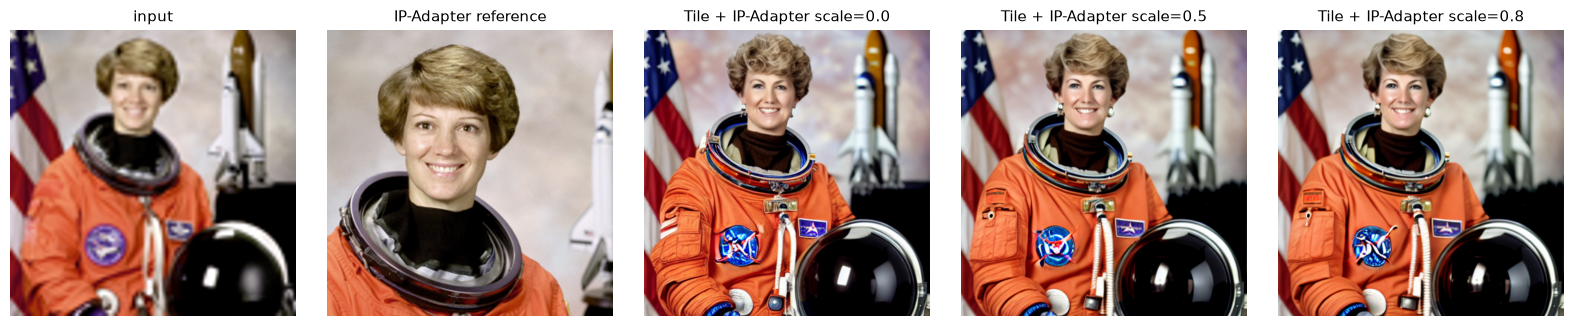

IP scale=0.0: PSNR 16.52 dB, SSIM 0.507
IP scale=0.5: PSNR 16.75 dB, SSIM 0.525
IP scale=0.8: PSNR 16.68 dB, SSIM 0.525
GPUメモリ使用量(ピーク): 6.03 GB


In [6]:
pipe.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")
ref = load_sample("astronaut").crop((100, 0, 400, 300)).resize((512, 512))   # 参照画像（高画質な部分）
results = {}
for scale in (0.0, 0.5, 0.8):
    pipe.set_ip_adapter_scale(scale)
    results[scale] = pipe(PROMPT, image=lq, control_image=lq, ip_adapter_image=ref, strength=0.9,
                          negative_prompt=NEG, num_inference_steps=30, generator=gen()).images[0]
show([lq, ref] + list(results.values()), ["input", "IP-Adapter reference"] +
     [f"Tile + IP-Adapter scale={s}" for s in results], size=3.2)
for s, im in results.items():
    print(f"IP scale={s}: PSNR {psnr(im, hr):.2f} dB, SSIM {ssim(im, hr):.3f}")
gpu_mem()

## 5.【実践例】スライド「ControlNet × img2img × IP-Adapter」の5段階を実際に実行する
スライドの「① 前処理 → ② 構造で縛る → ③ 色を縛る → ④ 質感で縛る → ⑤ 後処理」を、1枚の画像で順に実行します。

**処理のつながり（直列か？）**
- ① → ⑤ は直列：① の出力（下地）が、拡散モデルの入力になり、拡散モデルの出力を ⑤ で後処理します
- ②③④ は **1回の拡散生成の中で同時にかける3つの縛り** です（ControlNet＝構造、img2img の開始画像＝色、IP-Adapter＝質感）
- 下の図では効果が分かるように、縛りを1つずつ **足していった** 結果を並べます（②③ → ②③＋④）

設定
- 入力：高画質な人物写真（Kodak kodim04）を 1/4 に縮小し、ノイズと強い JPEG 圧縮を加えた「古いカメラ画像」相当
- ① Real-ESRGAN で 4 倍拡大しつつノイズ・圧縮ノイズを除去（忠実な下地）
- ②③ 下地を ControlNet Tile の **条件画像** にし、同じ下地から img2img（strength 0.6）で描き直す
- ④ IP-Adapter（scale 0.5）に **同じ人物の高画質な写真** を参照として与える。
  ここでは別の写真が無いので、元の写真を左右反転したもので代用しています（実務では、同じ対象を別に撮った高画質画像・良品画像を使う）
- ⑤ 色・明るさ（低周波）を下地 ① に合わせ、細部（高周波）は生成結果を残す（Wavelet 型カラー補正）

D:\seminar_env\venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\seminar_env\venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


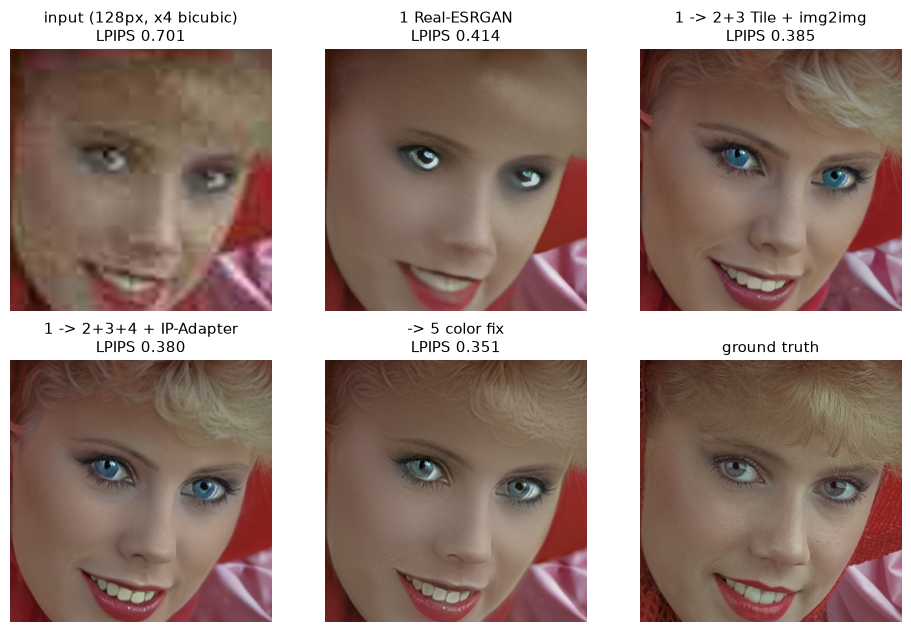

input (128px, x4 bicubic)    PSNR 25.74 dB  LPIPS 0.701
1 Real-ESRGAN                PSNR 25.92 dB  LPIPS 0.414
1 -> 2+3 Tile + img2img      PSNR 23.32 dB  LPIPS 0.385
1 -> 2+3+4 + IP-Adapter      PSNR 23.60 dB  LPIPS 0.380
-> 5 color fix               PSNR 25.30 dB  LPIPS 0.351


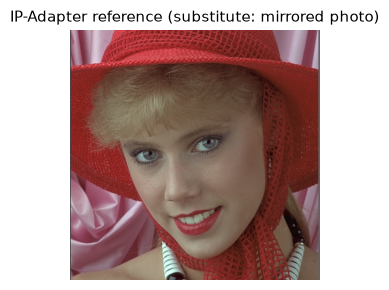

In [7]:
import spandrel
import lpips
from io import BytesIO

hr_p = load_portrait()                                            # 正解（評価用。処理には使わない）
small = hr_p.resize((128, 128), Image.BICUBIC)
noisy = np.clip(to_np(small) + np.random.default_rng(0).normal(0, 0.03, (128, 128, 3)), 0, 1)
buf = BytesIO(); to_pil(noisy).save(buf, "JPEG", quality=30)
lq_in = Image.open(buf).convert("RGB")                             # 128x128 の劣化入力

# ① 前処理：Real-ESRGAN
esr = spandrel.ModelLoader().load_from_file(
    download("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth")).to(DEVICE).eval()
with torch.no_grad():
    base = tensor_to_pil(esr(to_tensor(lq_in).to(DEVICE)))
del esr

# ④ で使う参照画像：同じ人物の高画質写真（ここでは元写真の左右反転で代用）
kod = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
ref_p = kod.transpose(Image.FLIP_LEFT_RIGHT).crop((0, 100, 512, 612))

P_PROMPT = "a high quality portrait photo of a blonde woman wearing a red hat, detailed skin, sharp focus"
def diffuse(ip_scale):
    pipe.set_ip_adapter_scale(ip_scale)                           # IP-Adapter を読み込んだ後は scale=0 でも参照画像の指定が必要
    return pipe(P_PROMPT, image=base, control_image=base, ip_adapter_image=ref_p, strength=0.6,
                negative_prompt=NEG, num_inference_steps=30, controlnet_conditioning_scale=1.0,
                guidance_scale=6.0, generator=gen()).images[0]

step23 = diffuse(0.0)     # ②③ ControlNet Tile（構造）＋ img2img（下地から開始＝色）
step4 = diffuse(0.5)      # ②③＋④ IP-Adapter（参照の質感）

# ⑤ 後処理：Wavelet 型カラー補正（低周波＝色・明るさは下地、高周波＝細部は生成結果）
def color_fix(out, ref, sigma=3):
    o, r = to_np(out), to_np(ref)
    return to_pil(o - cv2.GaussianBlur(o, (0, 0), sigma) + cv2.GaussianBlur(r, (0, 0), sigma))

step5 = color_fix(step4, base)

lp_ = lpips.LPIPS(net="alex", verbose=False).to(DEVICE)
def lp_score(a):
    with torch.no_grad():
        return lp_(to_tensor(a).to(DEVICE) * 2 - 1, to_tensor(hr_p).to(DEVICE) * 2 - 1).item()

stages = {"input (128px, x4 bicubic)": lq_in.resize((512, 512), Image.BICUBIC), "1 Real-ESRGAN": base,
          "1 -> 2+3 Tile + img2img": step23, "1 -> 2+3+4 + IP-Adapter": step4, "-> 5 color fix": step5}
box_p = (110, 40, 430, 360)
show([im.crop(box_p) for im in stages.values()] + [hr_p.crop(box_p)],
     [f"{k}\nLPIPS {lp_score(v):.3f}" for k, v in stages.items()] + ["ground truth"], size=3.2, rows=2)
for k, v in stages.items():
    print(f"{k:28s} PSNR {psnr(v, hr_p):.2f} dB  LPIPS {lp_score(v):.3f}")
show([ref_p], ["IP-Adapter reference (substitute: mirrored photo)"], size=3)

**観察ポイント**（LPIPS：見た目の差。低いほど正解に近い）
- ① ノイズ・ブロックは消えるが、肌や髪が「塗り絵」状になる（GAN 系の典型）
- ②③ 拡散モデルが髪・まつ毛・肌の質感を描き足す。ControlNet Tile が構造を、img2img の開始画像が色を固定するので、顔の形・表情は保たれる
- ④ 参照画像の質感・色味が加わり、髪の流れや目の色が正解に近づく
- ⑤ 拡散モデルでずれた色・明るさを下地に戻す → 見た目も数値も最良
- PSNR（画素の一致）は ②③ で一度下がる：描き足した細部は「もっともらしい」が画素単位では正解と一致しないため。⑤ で一部戻る
- **必ず入力と並べて、変わってはいけない部分が変わっていないか確認する**（参照の質感は強く移るので、参照画像の選び方と scale が重要）

## まとめ：何で縛るか
| 縛りたいもの | 手段 | 備考 |
|---|---|---|
| 構図・形 | ControlNet（Tile / Canny / Depth） | Tile は復元・超解像向き |
| 色・明るさ | img2img の strength を下げる / 色補正（Wavelet color fix） | |
| 質感・意味・同一性 | IP-Adapter（参照画像）、テキストプロンプト、LoRA | 良品画像を参照に使える |
| 観測との整合 | 残差射影（ノートブック08） | ハルシネーション抑制 |

**実践アプローチ**：低品質な合成画像（CG・古いカメラ画像）は「ControlNet Tile で構造を固定 → img2img で高品質化 → IP-Adapter で良品の質感を参照」の併用が効果的です。